# Fraud Detection with CatBoost: 2025 Historical Data & 2026 Forecasting

This notebook outlines the development of a Machine Learning model to automate the identification of potentially fraudulent transactions. The goal is to balance the reduction of financial losses with the preservation of a frictionless experience for legitimate customers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay

# Set visual style
sns.set_theme(style="whitegrid")

# Load historical data
df_2025 = pd.read_csv("transacoes_historico_2025.csv")

print(f"Dataset shape: {df_2025.shape}")
print(f"Overall Fraud Rate: {df_2025['flag_fraude'].mean() * 100:.2f}%")

Dataset shape: (523525, 15)
Overall Fraud Rate: 3.91%


## 2. Exploratory Data Analysis (EDA) on Quantitative Variables

Here, we explore the distributions of our main quantitative variables: `valor_transacao` (transaction amount) and `score_interno` (internal score). To reduce potential noise and avoid overfitting on highly specific decimal values, we truncate the cents from the transaction amounts.

C:\Users\mathe\AppData\Local\Temp\ipykernel_8260\2716120405.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_2025, x='flag_fraude', y='valor_transacao', ax=axes[1], palette="Set2")


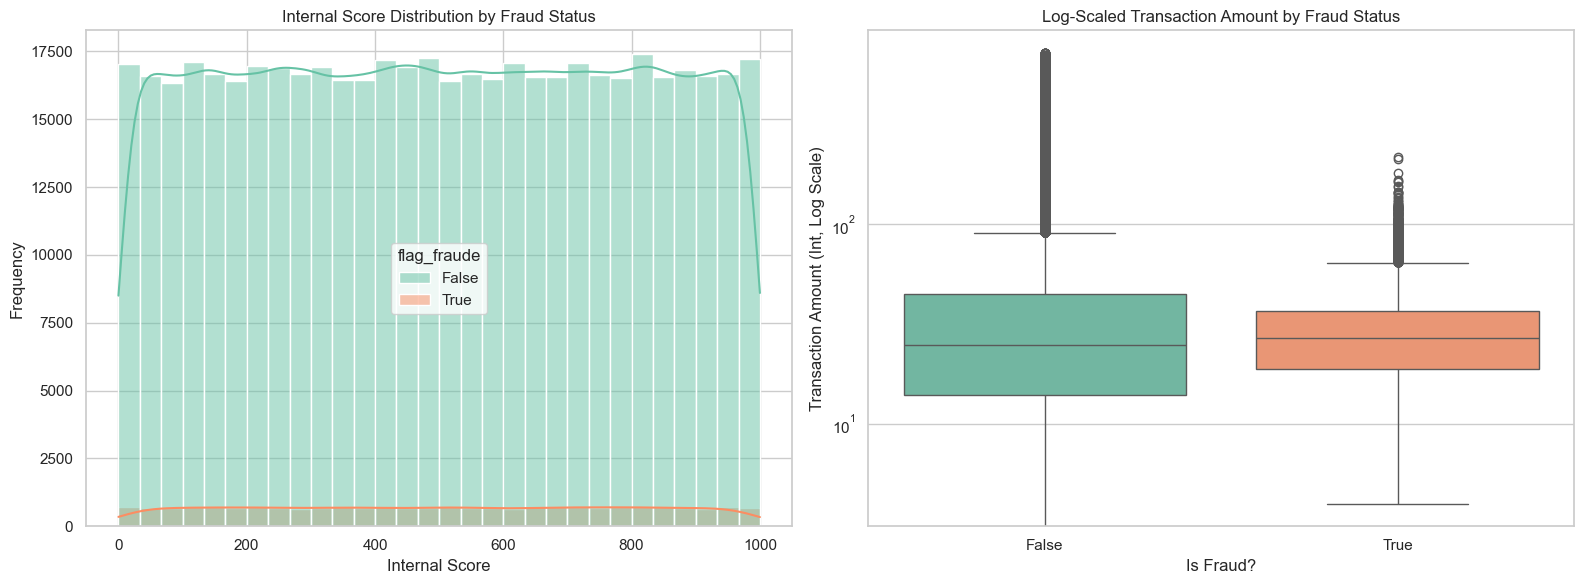

In [2]:
# Truncating cents from the transaction amount
df_2025['valor_transacao'] = df_2025['valor_transacao'].astype(int)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# EDA: Internal Score Distribution
sns.histplot(data=df_2025, x='score_interno', hue='flag_fraude', bins=30, kde=True, ax=axes[0], palette="Set2")
axes[0].set_title('Internal Score Distribution by Fraud Status')
axes[0].set_xlabel('Internal Score')
axes[0].set_ylabel('Frequency')

# EDA: Transaction Amount Boxplot (with truncated cents)
# We apply a logarithmic scale due to potential heavy-tailed spending amounts
sns.boxplot(data=df_2025, x='flag_fraude', y='valor_transacao', ax=axes[1], palette="Set2")
axes[1].set_yscale('log')
axes[1].set_title('Log-Scaled Transaction Amount by Fraud Status')
axes[1].set_xlabel('Is Fraud?')
axes[1].set_ylabel('Transaction Amount (Int, Log Scale)')

plt.tight_layout()
plt.show()

## 2.1. Exploratory Data Analysis (EDA) on Qualitative Variables

In addition to numerical data, understanding how fraud distributes across categorical variables is crucial for business insights. Here, we analyze the relationship between fraudulent transactions and qualitative features such as `turno` (shift), `device_type`, and `cidade_regiao` (region).

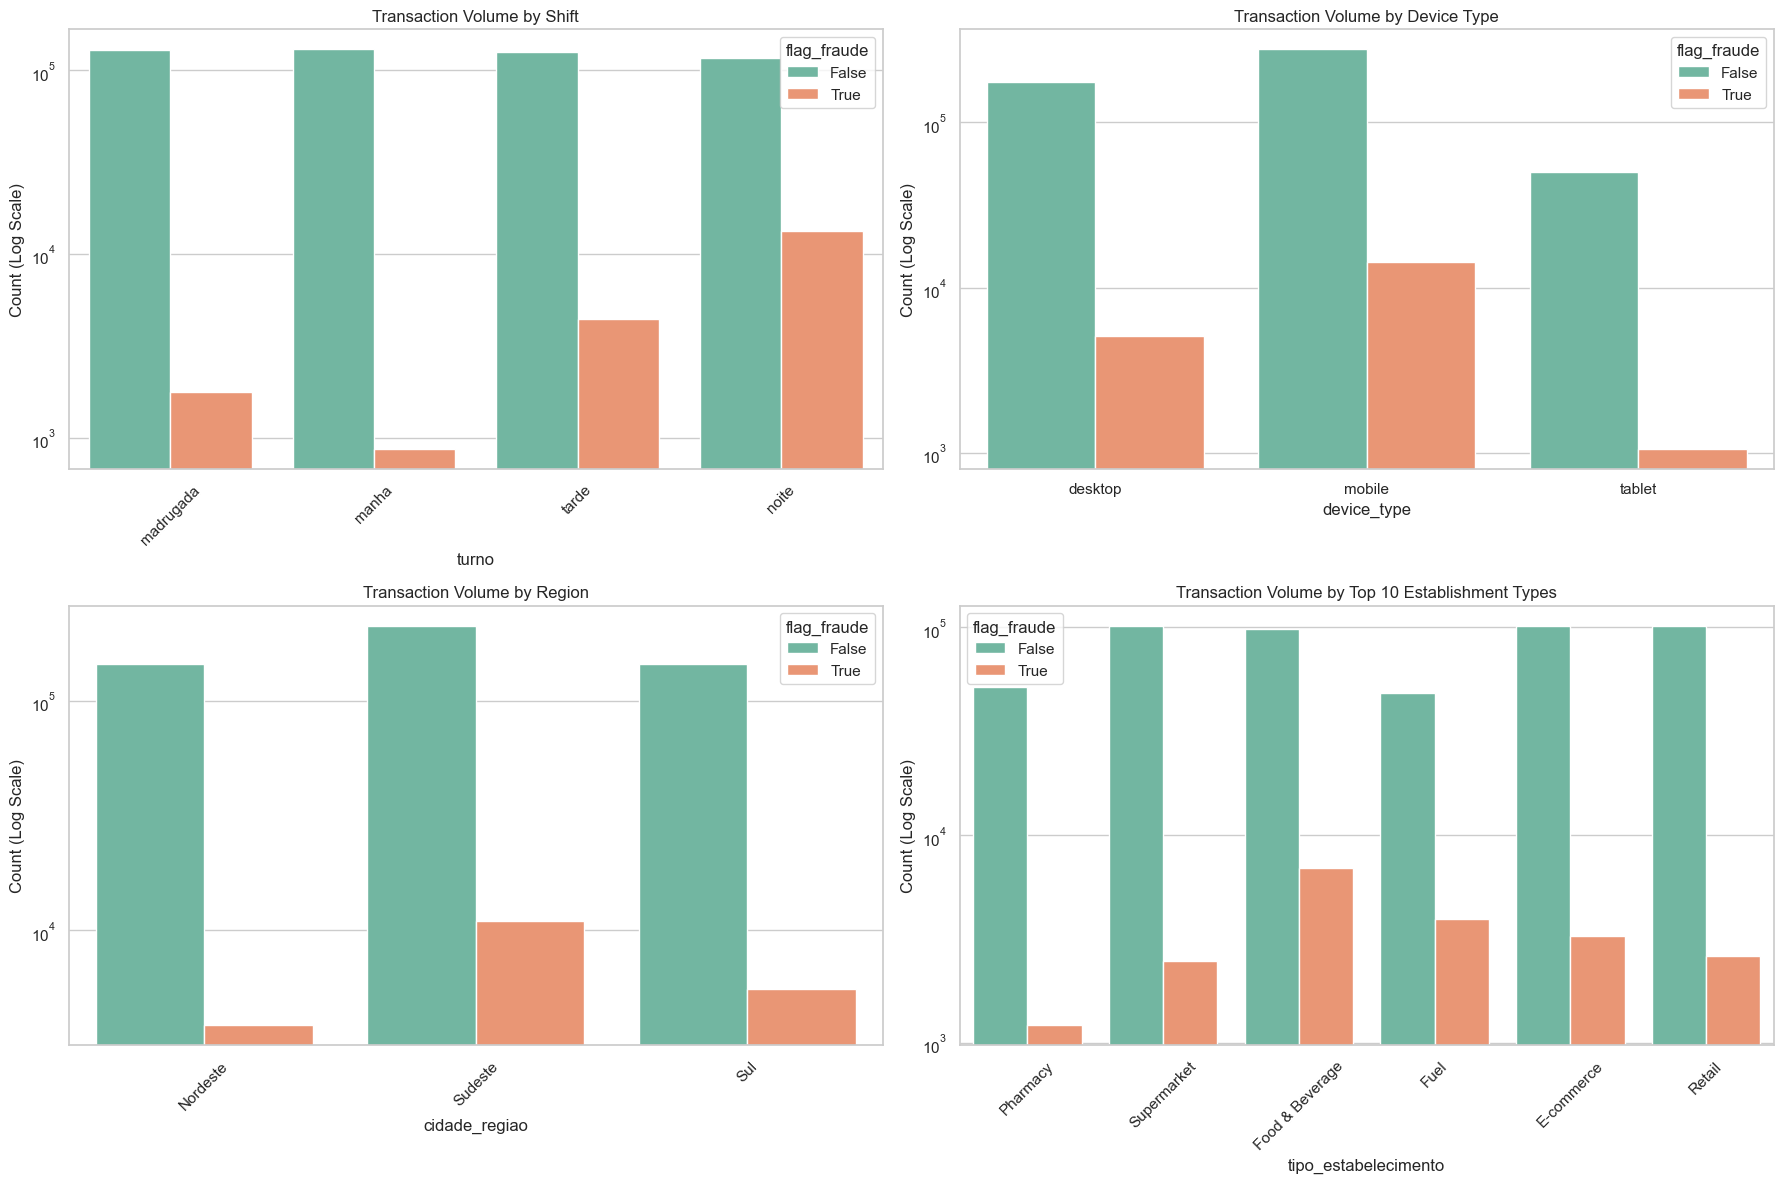

Fraud Rate (%) by Top 5 Establishment Types:
tipo_estabelecimento
Fuel               7.547495
Food & Beverage    6.629090
E-commerce         3.124792
Retail             2.506498
Supermarket        2.374670
Name: flag_fraude, dtype: float64


In [10]:
# ==========================================
# 2.1 Exploratory Data Analysis (EDA) on Qualitative Variables
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

# Create a 2x2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Plot 1: Transactions by Shift (Turno)
sns.countplot(data=df_2025, x='turno', hue='flag_fraude', ax=axes[0, 0], palette="Set2")
axes[0, 0].set_title('Transaction Volume by Shift')
axes[0, 0].set_yscale('log') # Log scale to better visualize the minority class
axes[0, 0].set_ylabel('Count (Log Scale)')
axes[0, 0].tick_params(axis='x', rotation=45)

# Plot 2: Transactions by Device Type
sns.countplot(data=df_2025, x='device_type', hue='flag_fraude', ax=axes[0, 1], palette="Set2")
axes[0, 1].set_title('Transaction Volume by Device Type')
axes[0, 1].set_yscale('log')
axes[0, 1].set_ylabel('Count (Log Scale)')

# Plot 3: Transactions by Region (Cidade Regiao)
sns.countplot(data=df_2025, x='cidade_regiao', hue='flag_fraude', ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title('Transaction Volume by Region')
axes[1, 0].set_yscale('log')
axes[1, 0].set_ylabel('Count (Log Scale)')
axes[1, 0].tick_params(axis='x', rotation=45)

# Plot 4: Transactions by Establishment Type (Tipo Estabelecimento)
# We select the top 10 most frequent establishment types to avoid cluttering the x-axis
top_estabelecimentos = df_2025['tipo_estabelecimento'].value_counts().nlargest(10).index
sns.countplot(data=df_2025[df_2025['tipo_estabelecimento'].isin(top_estabelecimentos)], 
              x='tipo_estabelecimento', hue='flag_fraude', ax=axes[1, 1], palette="Set2")
axes[1, 1].set_title('Transaction Volume by Top 10 Establishment Types')
axes[1, 1].set_yscale('log')
axes[1, 1].set_ylabel('Count (Log Scale)')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Displaying Fraud Rate (%) for the newly added variable
fraud_rate_by_estab = df_2025.groupby('tipo_estabelecimento')['flag_fraude'].mean() * 100
print("Fraud Rate (%) by Top 5 Establishment Types:")
print(fraud_rate_by_estab.sort_values(ascending=False).head())

## 3. Feature Engineering Pipeline

To avoid code duplication and ensure our 2026 test data undergoes the exact same transformations as our 2025 training data, we wrap our logic in a reusable pipeline function. We extract temporal patterns and calculate the client's 24-hour transaction velocity—a strong indicator of automated or frantic fraudulent behavior.

In [3]:
def feature_engineering_pipeline(df):
    """Applies feature engineering and removes high-risk ID columns to prevent data leakage."""
    df_processed = df.copy()
    
    # 1. Truncate cents
    df_processed['valor_transacao'] = df_processed['valor_transacao'].astype(int)
    
    # 2. Time-based extractions
    df_processed['datahora_transacao'] = pd.to_datetime(df_processed['datahora_transacao'])
    df_processed['transaction_hour'] = df_processed['datahora_transacao'].dt.hour
    df_processed['day_of_week'] = df_processed['datahora_transacao'].dt.dayofweek
    df_processed['is_weekend'] = df_processed['day_of_week'].apply(lambda x: 1 if x >= 5 else 0)
    
    # 3. Client Behavior (Velocity)
    df_processed = df_processed.sort_values(by=['nome_cliente', 'datahora_transacao'])
    
    # Time since last transaction in minutes
    df_processed['time_since_last_trans'] = df_processed.groupby('nome_cliente')['datahora_transacao'].diff().dt.total_seconds() / 60
    df_processed['time_since_last_trans'] = df_processed['time_since_last_trans'].fillna(-1)
    
    # Transaction count in the last 24 hours
    df_indexed = df_processed.set_index('datahora_transacao')
    df_processed['transactions_last_24h'] = df_indexed.groupby('nome_cliente').rolling('24h')['valor_transacao'].count().reset_index(drop=True)
    
    # 4. Safe Drop
    columns_to_remove = ['datahora_transacao', 'nome_cliente', 'nome_estabelecimento', 'codigo_postal']
    df_processed = df_processed.drop(columns=columns_to_remove)
    
    return df_processed

# Apply pipeline to the 2025 dataset
df_2025_engineered = feature_engineering_pipeline(df_2025)
print(f"Engineered Dataset Shape: {df_2025_engineered.shape}")

Engineered Dataset Shape: (523525, 16)


## 4. Internal Validation Split (Holdout)
Even though we have a separate 2026 dataset, it lacks the fraud labels. To properly evaluate our model's confusion matrix and business impact before deploying it, we must split our historical 2025 data. We will reserve 20% of 2025 exclusively for internal evaluation.

In [4]:
# Separate features (X) and target (y)
X = df_2025_engineered.drop(columns=['flag_fraude'])
y = df_2025_engineered['flag_fraude'].astype(int)

# Identify categorical features for CatBoost
cat_features = X.select_dtypes(include=['object', 'bool']).columns.tolist()

# 80/20 Split on historical data
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set: {X_train.shape} | Internal Validation set: {X_val.shape}")

Training set: (418820, 15) | Internal Validation set: (104705, 15)


## 5. Hyperparameter Tuning with K-Fold Cross-Validation
Just like coordinating a crew across different water conditions, K-Fold cross-validation ensures our model's performance relies on synchronized, stable behavior rather than a single lucky split. The `RandomizedSearchCV` handles this inherently via the `cv=5` parameter.

In [5]:
# Define base model
base_model = CatBoostClassifier(
    eval_metric='AUC',
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=0
)

# Search space (kept identical as requested to manage training time)
param_dist = {
    'depth': [4, 6, 8, 10],
    'learning_rate': [0.01, 0.05, 0.1],
    'iterations': [200, 300, 400],
    'l2_leaf_reg': [1, 3, 5, 10]
}

print("Starting Hyperparameter Tuning...")
random_search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_dist,
    n_iter=5, 
    scoring='roc_auc',
    cv=3, 
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train, cat_features=cat_features)

print(f"Best Validation ROC-AUC Score: {random_search.best_score_:.4f}")
print("Best Hyperparameters:")
for param, value in random_search.best_params_.items():
    print(f"  - {param}: {value}")

best_model = random_search.best_estimator_

Starting Hyperparameter Tuning...
Best Validation ROC-AUC Score: 0.9839
Best Hyperparameters:
  - learning_rate: 0.05
  - l2_leaf_reg: 10
  - iterations: 200
  - depth: 8


## 6. Internal Validation & Business Impact Assessment
We now apply our tuned model to the 20% holdout set from 2025 to gauge the real-world operational impact.

=== Internal Validation Classification Report ===
              precision    recall  f1-score   support

           0       1.00      0.93      0.96    100608
           1       0.36      0.99      0.53      4097

    accuracy                           0.93    104705
   macro avg       0.68      0.96      0.75    104705
weighted avg       0.97      0.93      0.95    104705

ROC-AUC: 0.9843
PR-AUC: 0.6802

--- Business Impact Summary ---
True Negatives (Legitimate, Approved): 93508
False Positives (Legitimate, Blocked - Customer Friction): 7100
False Negatives (Fraud, Approved - Financial Loss): 32
True Positives (Fraud, Blocked - Saved Revenue): 4065


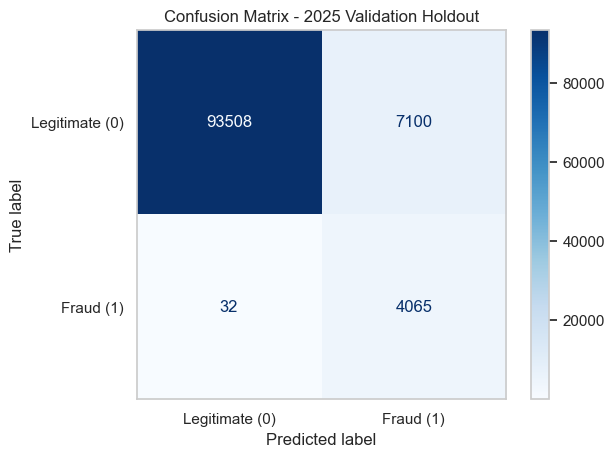

C:\Users\mathe\AppData\Local\Temp\ipykernel_8260\3667663907.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_importance.head(10), x='Importance', y='Feature', palette='viridis')


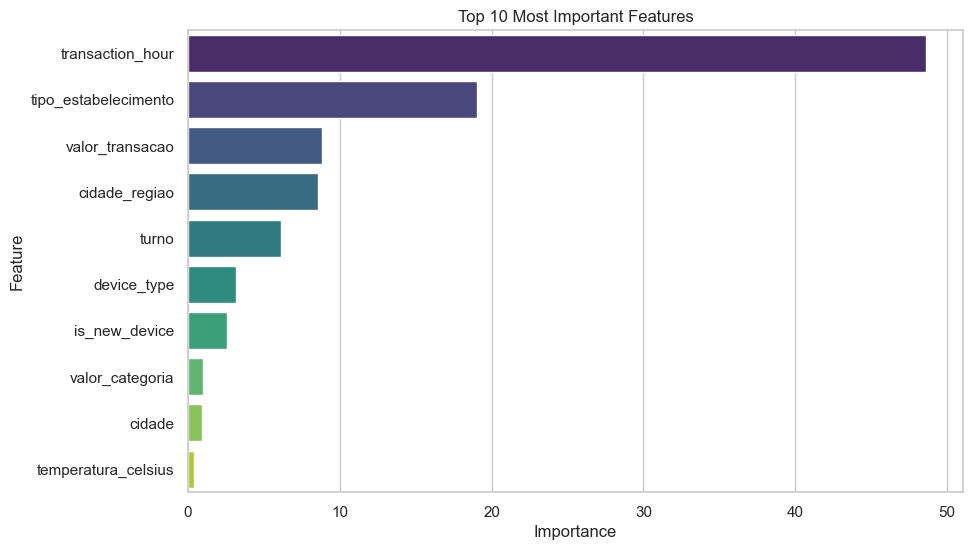

In [6]:
# Predict on the 2025 validation set
y_val_pred = best_model.predict(X_val)
y_val_proba = best_model.predict_proba(X_val)[:, 1]

print("=== Internal Validation Classification Report ===")
print(classification_report(y_val, y_val_pred))
print(f"ROC-AUC: {roc_auc_score(y_val, y_val_proba):.4f}")
print(f"PR-AUC: {average_precision_score(y_val, y_val_proba):.4f}")

# Business Impact via Confusion Matrix
cm = confusion_matrix(y_val, y_val_pred)
tn, fp, fn, tp = cm.ravel()

print("\n--- Business Impact Summary ---")
print(f"True Negatives (Legitimate, Approved): {tn}")
print(f"False Positives (Legitimate, Blocked - Customer Friction): {fp}")
print(f"False Negatives (Fraud, Approved - Financial Loss): {fn}")
print(f"True Positives (Fraud, Blocked - Saved Revenue): {tp}")

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Legitimate (0)', 'Fraud (1)'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - 2025 Validation Holdout')
plt.grid(False)
plt.show()

# Feature Importance
importances = best_model.get_feature_importance()
features = best_model.feature_names_
df_importance = pd.DataFrame({'Feature': features, 'Importance': importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_importance.head(10), x='Importance', y='Feature', palette='viridis')
plt.title('Top 10 Most Important Features')
plt.show()

## 7. Production Preparation and 2026 Drift Analysis
Now that the model is thoroughly validated, we train it on the **entirety** of the 2025 dataset to maximize its learning. Then, we apply it to the new `transacoes_jan2026.csv` dataset to generate our final predictions and analyze the predicted fraud rate for potential Data Drift.

In [7]:
# 1. Retrain on 100% of the 2025 Data for Production
print("Retraining final model on 100% of 2025 historical data...")
production_model = CatBoostClassifier(
    **random_search.best_params_,
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=0
)
production_model.fit(X, y, cat_features=cat_features)

# 2. Load and process the 2026 test dataset
df_2026 = pd.read_csv("transacoes_jan2026.csv")
print(f"\nLoaded January 2026 Data. Shape: {df_2026.shape}")

# Process through the exact same feature engineering pipeline
X_2026 = feature_engineering_pipeline(df_2026)

# 3. Generate Predictions
predictions_2026 = production_model.predict(X_2026)
predict_proba_2026 = production_model.predict_proba(X_2026)[:, 1]

# 4. Drift Analysis
historical_fraud_rate = y.mean() * 100
predicted_fraud_rate_2026 = predictions_2026.mean() * 100

print("\n=== Drift Analysis: January 2026 ===")
print(f"Historical 2025 Fraud Rate: {historical_fraud_rate:.2f}%")
print(f"Predicted 2026 Fraud Rate:  {predicted_fraud_rate_2026:.2f}%")
print(f"Total Transactions Flagged as Fraud in Jan 2026: {predictions_2026.sum()}")

if abs(predicted_fraud_rate_2026 - historical_fraud_rate) > 2.0:
    print("\n[WARNING] Significant deviation in fraud rate detected.")
    print("Hypothesis: Potential Data Drift or coordinated seasonal fraud attack in January.")
else:
    print("\n[OK] The predicted fraud rate aligns with historical behavior. No immediate drift detected.")

Retraining final model on 100% of 2025 historical data...

Loaded January 2026 Data. Shape: (44451, 14)

=== Drift Analysis: January 2026 ===
Historical 2025 Fraud Rate: 3.91%
Predicted 2026 Fraud Rate:  10.65%
Total Transactions Flagged as Fraud in Jan 2026: 4732

[WARNING] Significant deviation in fraud rate detected.
Hypothesis: Potential Data Drift or coordinated seasonal fraud attack in January.


In [9]:
# ==========================================
# 8. Exporting 2026 Predictions to CSV
# ==========================================
print("Preparing to export 2026 predictions...")

# Create a copy of the original 2026 dataset to preserve all original columns
df_2026_results = df_2026.copy()

# Append the model's binary prediction and probability score
df_2026_results['predicted_is_fraud'] = predictions_2026
df_2026_results['fraud_probability_score'] = predict_proba_2026

# Define the output filename
output_filename = "transacoes_jan2026_classified.csv"

# Export to CSV (without the index column)
df_2026_results.to_csv(output_filename, index=False)

print(f"[SUCCESS] Classified data successfully exported to: {output_filename}")
print(df_2026_results[['nome_cliente', 'valor_transacao', 'predicted_is_fraud', 'fraud_probability_score']].head())

Preparing to export 2026 predictions...
[SUCCESS] Classified data successfully exported to: transacoes_jan2026_classified.csv
    nome_cliente  valor_transacao  predicted_is_fraud  fraud_probability_score
0  Cliente_16241            21.72                   0                 0.010997
1  Cliente_10027            28.70                   0                 0.002318
2  Cliente_13606            34.55                   0                 0.000003
3   Cliente_7302            57.53                   0                 0.002426
4  Cliente_20061           149.50                   0                 0.012528
